# 03 Weather EDA + Random Forest


## 1. Импорт библиотек

In [23]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Настраиваем отображение, чтобы графики и таблицы были удобнее читать.
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

# Фиксируем случайность для воспроизводимости результата модели.
RANDOM_STATE = 42


## 2. Загрузка данных


In [24]:
candidate_paths = [
    Path("data/processed/SeoulBikeData_clean.csv"),          # Jupyter запущен из корня проекта
    Path("../data/processed/SeoulBikeData_clean.csv"),       # Jupyter запущен из notebooks
]

data_path = next((p for p in candidate_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Не найден SeoulBikeData_clean.csv. Положи файл в data/processed/ "
        "или поправь candidate_paths в этой ячейке."
    )

print("Загружаем:", data_path.resolve())
df = pd.read_csv(data_path, parse_dates=["Date"])

print("Размер датасета:", df.shape)
display(df.head())


Загружаем: C:\Users\VMA\Desktop\seoul-bike-project\data\processed\SeoulBikeData_clean.csv
Размер датасета: (8760, 14)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## 3. Первичная проверка

In [25]:
print("Период:", df["Date"].min(), "—", df["Date"].max())
print("Пропусков всего:", df.isna().sum().sum())
print("Дубликатов:", df.duplicated().sum())
print("\\nТипы колонок:")
display(df.dtypes.to_frame("dtype"))

weather_columns = [
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Solar Radiation (MJ/m2)",
    "Rainfall(mm)",
    "Snowfall (cm)",
]
display(df[weather_columns + ["Rented Bike Count"]].describe().T)


Период: 2017-12-01 00:00:00 — 2018-11-30 00:00:00
Пропусков всего: 0
Дубликатов: 0
\nТипы колонок:


,dtype
Date,datetime64[us]
Rented Bike Count,int64
Hour,int64
Temperature(°C),float64
Humidity(%),int64
Wind speed (m/s),float64
Visibility (10m),int64
Dew point temperature(°C),float64
Solar Radiation (MJ/m2),float64
Rainfall(mm),float64


,count,mean,std,min,25%,50%,75%,max
Temperature(°C),8760.0,12.882922,11.944825,-17.8,3.5,13.70,22.50,39.40
Humidity(%),8760.0,58.226256,20.362413,0.0,42.0,57.00,74.00,98.00
Wind speed (m/s),8760.0,1.724909,1.036300,0.0,0.9,1.50,2.30,7.40
Solar Radiation (MJ/m2),8760.0,0.569111,0.868746,0.0,0.0,0.01,0.93,3.52
Rainfall(mm),8760.0,0.148687,1.128193,0.0,0.0,0.00,0.00,35.00
Snowfall (cm),8760.0,0.075068,0.436746,0.0,0.0,0.00,0.00,8.80
Rented Bike Count,8760.0,704.602055,644.997468,0.0,191.0,504.50,1065.25,3556.00


## 4. Анализ погоды и спроса

### 4.1 Температура и количество аренд

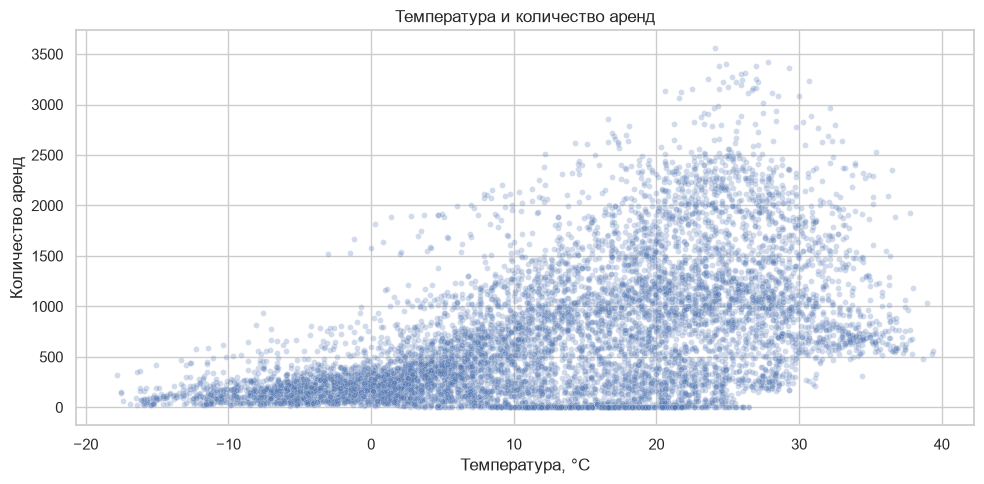

,temperature_group,mean,median,count
0,"[-20.0, -15.0)",105.568182,73.0,44
1,"[-15.0, -10.0)",150.576923,120.5,182
2,"[-10.0, -5.0)",177.925847,159.0,472
3,"[-5.0, 0.0)",228.149660,195.0,735
4,"[0.0, 5.0)",327.347170,274.0,1060
5,"[5.0, 10.0)",513.863216,440.5,1082
6,"[10.0, 15.0)",680.339388,653.5,1046
7,"[15.0, 20.0)",829.508671,779.0,1211
8,"[20.0, 25.0)",1041.085183,989.0,1397
9,"[25.0, 30.0)",1223.655412,1106.0,1007


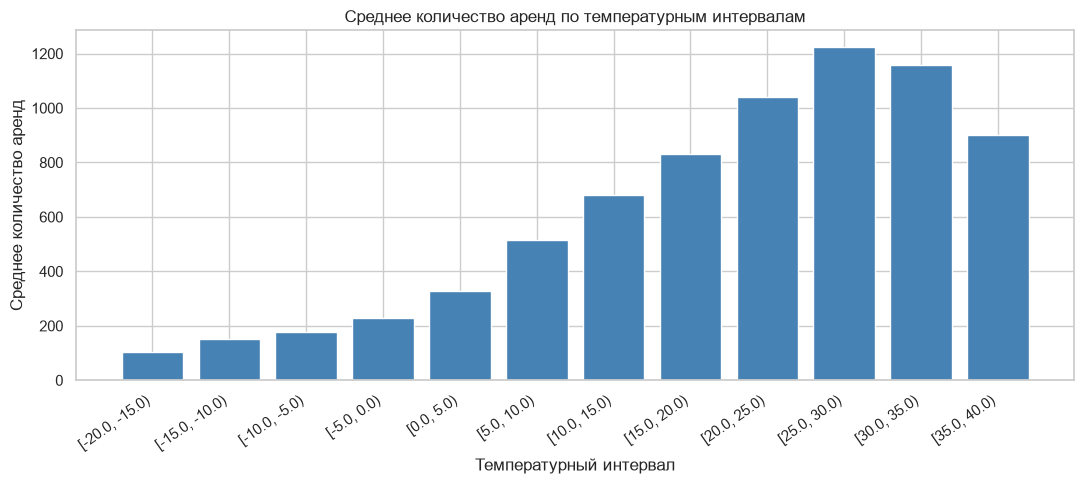

In [26]:
# Точечный график: каждая точка - один час наблюдения.
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="Temperature(°C)",
    y="Rented Bike Count",
    alpha=0.25,  
    s=18          
)
plt.title("Температура и количество аренд")
plt.xlabel("Температура, °C")
plt.ylabel("Количество аренд")
plt.tight_layout()
plt.show()

# группируем температуру по интервалам шириной 5 °C.
temp_bins = np.arange(
    np.floor(df["Temperature(°C)"].min() / 5) * 5,
    np.ceil(df["Temperature(°C)"].max() / 5) * 5 + 5,
    5
)
df["temperature_group"] = pd.cut(df["Temperature(°C)"], bins=temp_bins, right=False)

# Для каждого интервала считаем среднее, медиану и число часовых наблюдений.
temp_demand = (
    df.groupby("temperature_group", observed=False)["Rented Bike Count"]
      .agg(["mean", "median", "count"])
      .reset_index()
)
display(temp_demand)

# Столбчатый график среднего количества аренд по температурным группам.
plt.figure(figsize=(11, 5))
plt.bar(temp_demand["temperature_group"].astype(str), temp_demand["mean"], color="steelblue")
plt.title("Среднее количество аренд по температурным интервалам")
plt.xlabel("Температурный интервал")
plt.ylabel("Среднее количество аренд")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## Вывод:

С увеличением температуры повышается спрос на аренду, максимальное среднее значение достигается при температуре 25-30°C, и составляет 1223, при более высокой температуре наблюдается спад спроса

### 4.2 Влажность и спрос

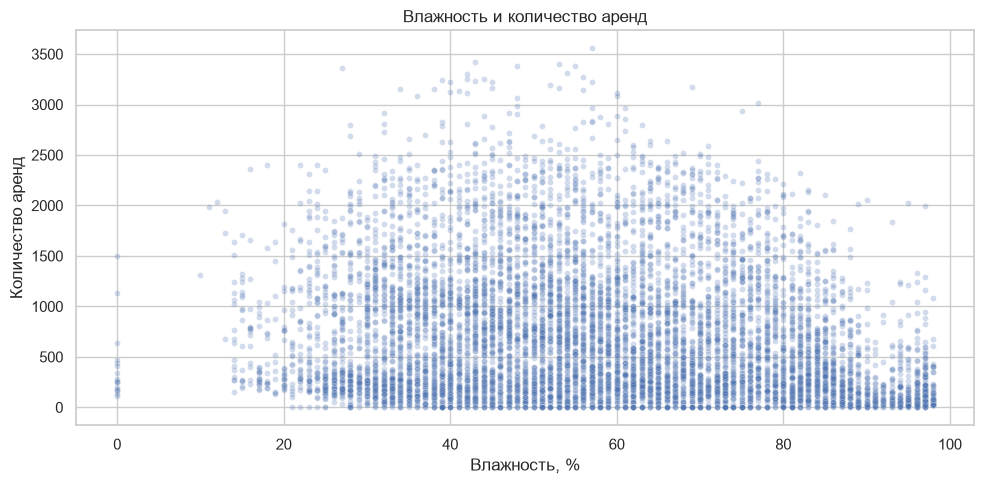

,humidity_group,mean,median,count
0,"(-0.1, 20.0]",667.697183,433.5,142
1,"(20.0, 40.0]",759.740331,568.0,1810
2,"(40.0, 60.0]",842.423090,704.0,2893
3,"(60.0, 80.0]",725.481867,531.0,2399
4,"(80.0, 100.0]",346.180739,201.5,1516


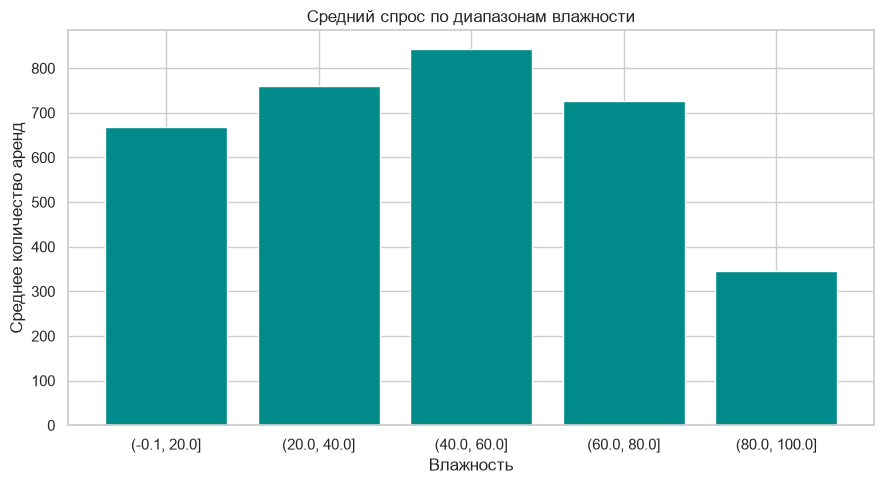

In [27]:
# Смотрим связь влажности и количества аренд на уровне отдельных часов.
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="Humidity(%)",
    y="Rented Bike Count",
    alpha=0.25,
    s=18
)
plt.title("Влажность и количество аренд")
plt.xlabel("Влажность, %")
plt.ylabel("Количество аренд")
plt.tight_layout()
plt.show()

# Делим влажность на интервалы и сравниваем спрос между группами.
humidity_bins = [-0.1, 20, 40, 60, 80, 100]
df["humidity_group"] = pd.cut(df["Humidity(%)"], bins=humidity_bins)
humidity_demand = (
    df.groupby("humidity_group", observed=False)["Rented Bike Count"]
      .agg(["mean", "median", "count"])
      .reset_index()
)
display(humidity_demand)

# Визуализируем средний спрос в каждом диапазоне влажности.
plt.figure(figsize=(9, 5))
plt.bar(humidity_demand["humidity_group"].astype(str), humidity_demand["mean"], color="darkcyan")
plt.title("Средний спрос по диапазонам влажности")
plt.xlabel("Влажность")
plt.ylabel("Среднее количество аренд")
plt.tight_layout()
plt.show()


## Вывод:

Наибольший спрос наблюдается при влажности 40-60% - около 842 аренд в среднем. При очень высокой влажности (80–100%) среднее количество аренд снижается примерно до 346.

### 4.3 Дождь и снег

Спрос при наличии/отсутствии дождя:


,mean,median,count
rain_present,,,
Есть дождь,163.456439,67.0,528
Нет дождя,739.311103,562.0,8232


Спрос при наличии/отсутствии снега:


,mean,median,count
snow_present,,,
Есть снег,185.101580,149.0,443
Нет снега,732.272935,557.0,8317


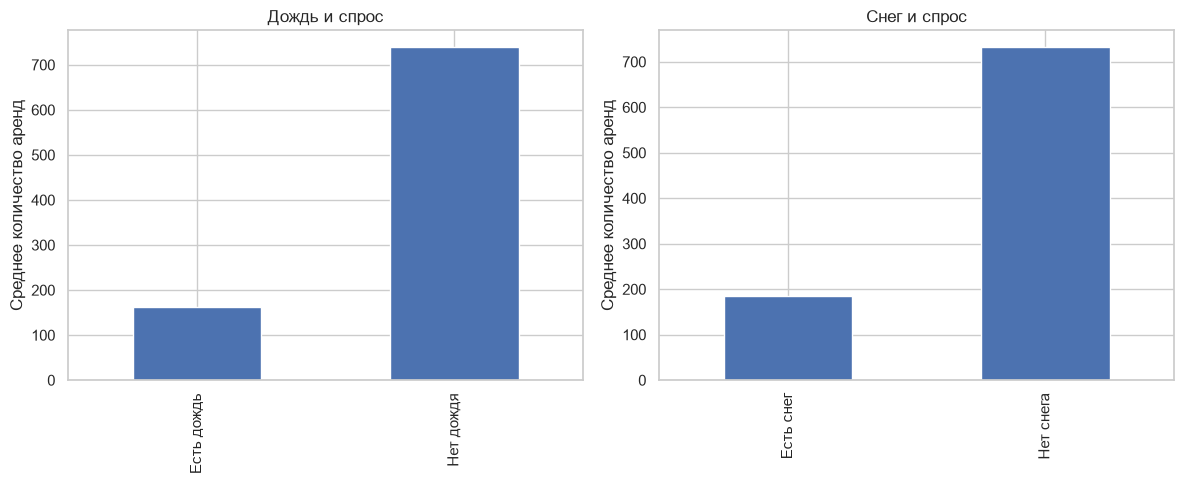

In [28]:
# Создаём категориальные признаки: был ли дождь/снег в конкретный час.
df["rain_present"] = np.where(df["Rainfall(mm)"] > 0, "Есть дождь", "Нет дождя")
df["snow_present"] = np.where(df["Snowfall (cm)"] > 0, "Есть снег", "Нет снега")

# Сравниваем среднее, медиану и число часовых записей в каждой группе.
rain_summary = df.groupby("rain_present")["Rented Bike Count"].agg(["mean", "median", "count"])
snow_summary = df.groupby("snow_present")["Rented Bike Count"].agg(["mean", "median", "count"])

print("Спрос при наличии/отсутствии дождя:")
display(rain_summary)
print("Спрос при наличии/отсутствии снега:")
display(snow_summary)

# Рисуем два графика: средний спрос при дожде и при снеге.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
rain_summary["mean"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Дождь и спрос")
axes[0].set_xlabel("")
axes[0].set_ylabel("Среднее количество аренд")

snow_summary["mean"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Снег и спрос")
axes[1].set_xlabel("")
axes[1].set_ylabel("Среднее количество аренд")

plt.tight_layout()
plt.show()


## Выводы:

В дождливые часы среднее количество аренд составляет около 163, тогда как в часы без дождя около 739. В часы со снегом среднее значение составляет около 185, а без снега около 732. Это свидетельствует о том что в плохую погоду спрос на аренду снижается


### 4.4 Ветер и солнечная радиация

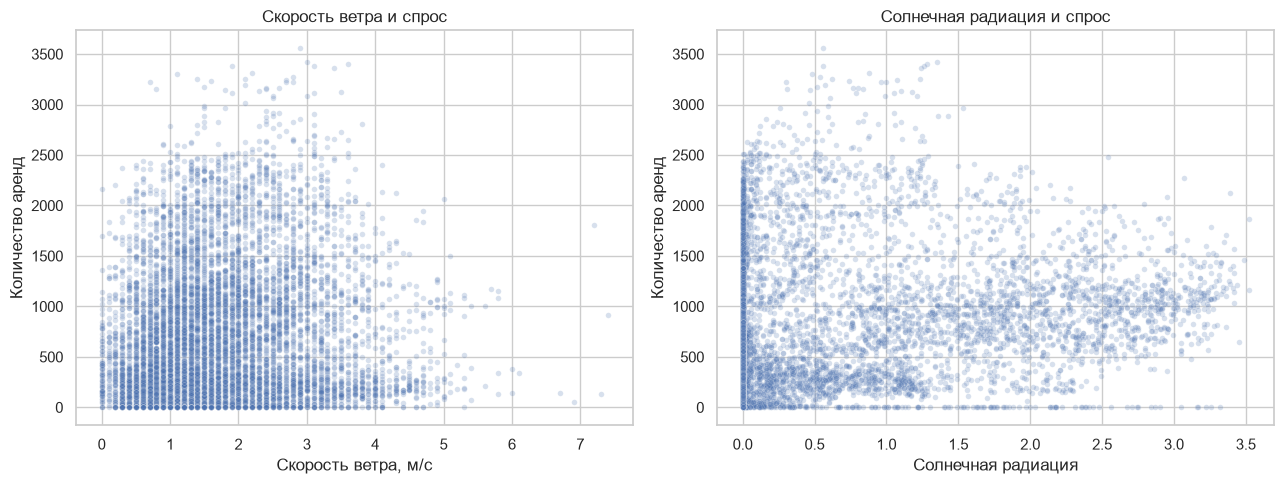

Спрос в зависимости от скорости ветра:


,mean,median,count
wind_group,,,
"(-0.101, 1.0]",527.59,334.0,2606
"(1.0, 2.0]",752.20,606.0,3314
"(2.0, 3.0]",858.68,719.0,1801
"(3.0, 4.0]",785.56,554.5,780
"(4.0, 5.0]",556.69,314.5,224
"(5.0, 6.0]",597.24,391.0,29
"(6.0, 10.0]",563.67,241.0,6


Спрос в зависимости от солнечной радиации:


,mean,median,count
solar_group,,,
"(-0.101, 0.1]",531.90,301.0,4879
"(0.1, 0.5]",841.19,492.0,993
"(0.5, 1.0]",906.29,644.0,813
"(1.0, 1.5]",952.63,827.0,637
"(1.5, 2.0]",967.04,913.0,520
"(2.0, 3.5]",974.16,991.0,916


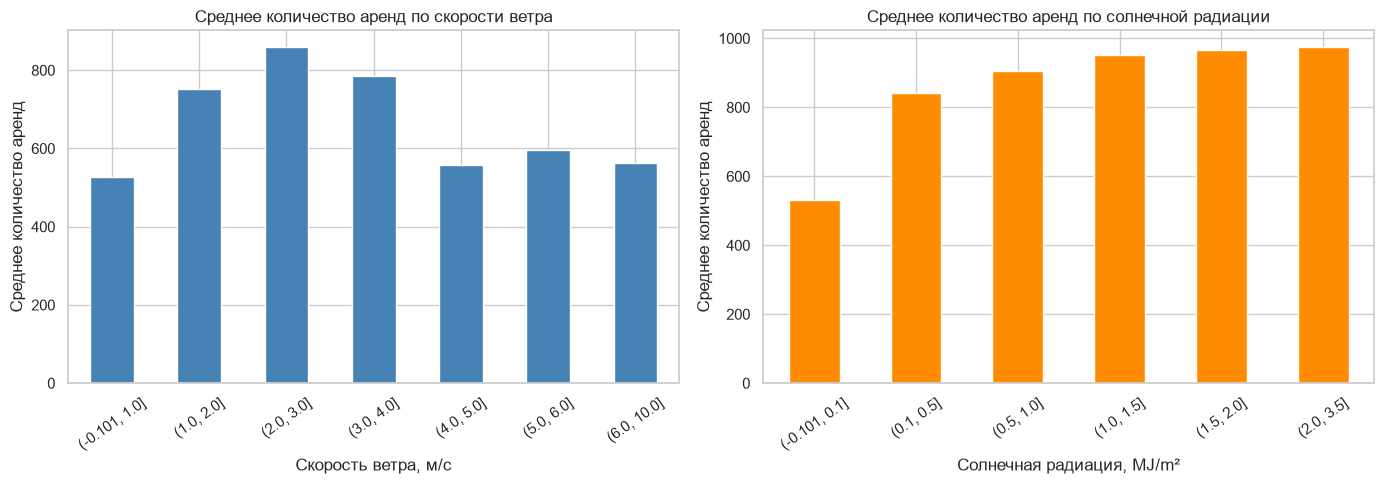

In [29]:
# Сначала сравниваем отдельные часовые наблюдения для ветра и солнечной радиации.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df, x="Wind speed (m/s)", y="Rented Bike Count",
    alpha=0.22, s=16, ax=axes[0]
)
axes[0].set_title("Скорость ветра и спрос")
axes[0].set_xlabel("Скорость ветра, м/с")
axes[0].set_ylabel("Количество аренд")

sns.scatterplot(
    data=df, x="Solar Radiation (MJ/m2)", y="Rented Bike Count",
    alpha=0.22, s=16, ax=axes[1]
)
axes[1].set_title("Солнечная радиация и спрос")
axes[1].set_xlabel("Солнечная радиация")
axes[1].set_ylabel("Количество аренд")

plt.tight_layout()
plt.show()

# Группируем скорость ветра по интервалам.
df["wind_group"] = pd.cut(
    df["Wind speed (m/s)"],
    bins=[-0.1, 1, 2, 3, 4, 5, 6, 10],
    include_lowest=True
)

wind_table = df.groupby(
    "wind_group", observed=False
)["Rented Bike Count"].agg(
    mean="mean",
    median="median",
    count="count"
)

print("Спрос в зависимости от скорости ветра:")
display(wind_table.round(2))

# Группируем солнечную радиацию.
df["solar_group"] = pd.cut(
    df["Solar Radiation (MJ/m2)"],
    bins=[-0.1, 0.1, 0.5, 1, 1.5, 2, 3.5],
    include_lowest=True
)

solar_table = df.groupby(
    "solar_group", observed=False
)["Rented Bike Count"].agg(
    mean="mean",
    median="median",
    count="count"
)

print("Спрос в зависимости от солнечной радиации:")
display(solar_table.round(2))

# Для более наглядного сравнения строим средние значения по интервалам.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

wind_table["mean"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Среднее количество аренд по скорости ветра")
axes[0].set_xlabel("Скорость ветра, м/с")
axes[0].set_ylabel("Среднее количество аренд")
axes[0].tick_params(axis="x", rotation=35)

solar_table["mean"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Среднее количество аренд по солнечной радиации")
axes[1].set_xlabel("Солнечная радиация, MJ/m²")
axes[1].set_ylabel("Среднее количество аренд")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


## Выводы:
**Ветер:** наибольшее среднее количество аренд наблюдается при скорости ветра 2-3 м/с - около 859 велосипедов за час. При скорости выше 3 м/с средний спрос в целом снижается. Для скоростей выше 5 м/с наблюдений очень мало (35 суммарно), поэтому эти интервалы нельзя интерпретировать уверенно.

**Солнечная радиация:** при низкой солнечной радиации (до 0.1 MJ/m²) среднее количество аренд составляет около 532 велосипедов за час. При увеличении солнечной радиации до 2.0–3.5 MJ/m² показатель возрастает примерно до 974 за час. Это может свидетельствовать о том, что в более солнечную погоду спрос на прокат велосипедов выше.



### 4.5 Корреляции погодных признаков с количеством аренд

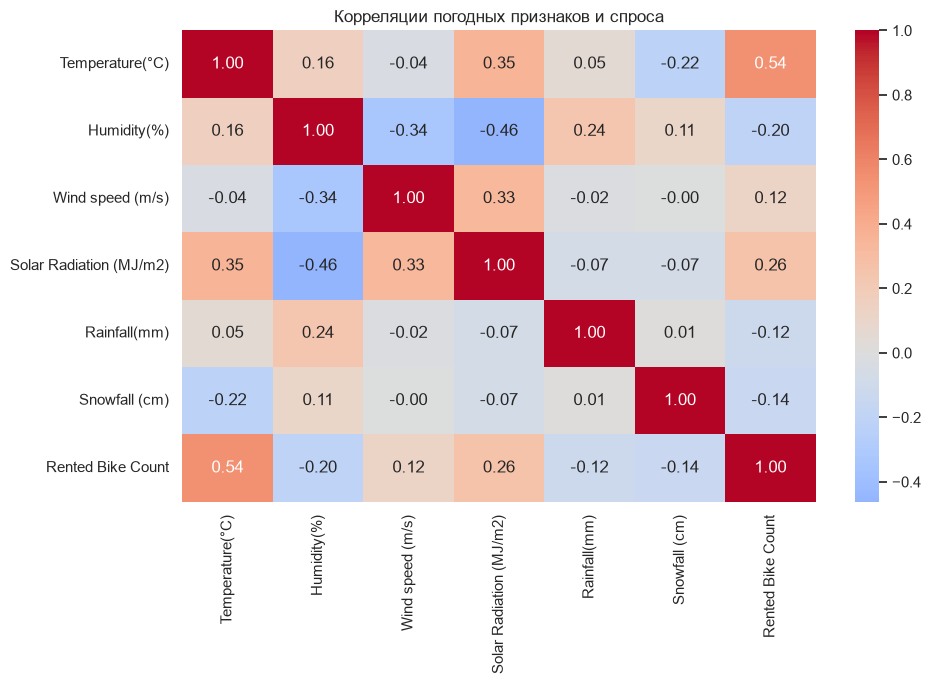

,Rented Bike Count
Temperature(°C),0.538558
Solar Radiation (MJ/m2),0.261837
Wind speed (m/s),0.121108
Rainfall(mm),-0.123074
Snowfall (cm),-0.141804
Humidity(%),-0.199780


In [30]:
# Оставляем погодные числовые признаки и целевую переменную.
correlation_columns = weather_columns + ["Rented Bike Count"]

# Считаем коэффициенты корреляции Пирсона между всеми выбранными столбцами.
corr = df[correlation_columns].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции погодных признаков и спроса")
plt.tight_layout()
plt.show()

display(
    corr[["Rented Bike Count"]]
    .drop(index="Rented Bike Count")
    .sort_values("Rented Bike Count", ascending=False)
)


## Выводы: 

Анализ корреляций показал, что среди погодных факторов наиболее сильную положительную связь с количеством аренд велосипедов имеет температура воздуха (0.539). Солнечная радиация также имеет положительную связь (0.262). Корреляции скорости ветра, влажности, дождя и снега относительно слабые.



## 5. Подготовка данных для Random Forest


In [31]:
# Повторно загружаем исходную таблицу для ML-части,
model_df = pd.read_csv(data_path, parse_dates=["Date"])

# Сортируем записи по времени
model_df = model_df.sort_values(["Date", "Hour"]).reset_index(drop=True)

# Создаём дополнительные календарные признаки из даты.
model_df["month"] = model_df["Date"].dt.month
model_df["day_of_week"] = model_df["Date"].dt.day_of_week

# y - целевая переменная, которую предсказываем.
y = model_df["Rented Bike Count"]

# X - входные признаки. Удаляем целевую переменную и саму дату.
X = model_df.drop(columns=["Rented Bike Count", "Date"])

# Целевая переменная не должна случайно попасть во входные признаки.
assert "Rented Bike Count" not in X.columns

# Делим данные хронологически: первые 80% обучение, последние 20% тест.
# Так тестовые наблюдения идут позже обучающих, как при прогнозировании будущего.
split = int(len(model_df) * 0.8)

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()
y_train = y.iloc[:split].copy()
y_test = y.iloc[split:].copy()

# Проверяем размеры выборок и границу дат, чтобы убедиться в корректности split.
print("Всего строк:", len(model_df))
print("TRAIN:", X_train.shape, y_train.shape)
print("TEST :", X_test.shape, y_test.shape)
print("Последняя дата TRAIN:", model_df.iloc[split - 1]["Date"].date())
print("Первая дата TEST :", model_df.iloc[split]["Date"].date())
print("\\nПризнаки:")
print(X.columns.tolist())


Всего строк: 8760
TRAIN: (7008, 14) (7008,)
TEST : (1752, 14) (1752,)
Последняя дата TRAIN: 2018-09-18
Первая дата TEST : 2018-09-19
\nПризнаки:
['Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day', 'month', 'day_of_week']


### 5.1 Настройка preprocessing

In [32]:
# Категориальные признаки.
categorical_features = ["Seasons", "Holiday", "Functioning Day"]

# Все остальные столбцы считаем числовыми признаками.
numeric_features = [col for col in X_train.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)


Числовые признаки: ['Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'month', 'day_of_week']
Категориальные признаки: ['Seasons', 'Holiday', 'Functioning Day']


## 6. Обучение Random Forest


In [33]:
rf_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),  # преобразуем числовые и категориальные признаки
    ("model", RandomForestRegressor(
        n_estimators=400,       # количество деревьев в ансамбле
        max_depth=None,         
        min_samples_split=2,    # минимум объектов для разделения узла
        min_samples_leaf=1,     # минимум объектов в конечном листе
        max_features=1.0,       # при поиске разделения рассматриваем все признаки
        n_jobs=-1,              # используем все доступные ядра процессора
        random_state=RANDOM_STATE,  # фиксируем случайность для повторяемости
    )),
])

# Обучаем весь pipeline только на TRAIN.
rf_pipeline.fit(X_train, y_train)
print("Random Forest обучен.")


Random Forest обучен.


## 7. Оценка качества модели


In [34]:
# Получаем первоначальные прогнозы модели на отложенной TEST-выборке.
y_pred_raw = rf_pipeline.predict(X_test)

# Заменяем отрицательные прогнозы нулём:
y_pred = np.clip(y_pred_raw, 0, None)

# Считаем метрики, сравнивая реальные значения с итоговыми прогнозами.
mae = mean_absolute_error(y_test, y_pred)  # средняя абсолютная ошибка
rmse = root_mean_squared_error(y_test, y_pred)  # сильнее штрафует большие ошибки
r2 = r2_score(y_test, y_pred)  # доля объяснённой моделью вариации целевой переменной

rf_results = pd.DataFrame([{
    "Model": "Random Forest",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2,
}])

display(rf_results.round(3))

# Проверяем, были ли отрицательные прогнозы до применения ограничения.
print(f"Минимальное предсказанное значение: {y_pred_raw.min():.2f}")


,Model,MAE,RMSE,R2
0,Random Forest,219.699,316.196,0.734


Минимальное предсказанное значение: 0.00


## 8. Фактические значения, прогноз и ошибки



In [35]:
# Собираем таблицу, где находятся реальные значения и прогнозы модели.
comparison = pd.DataFrame({
    "Date": model_df.loc[y_test.index, "Date"].to_numpy(), 
    "Hour": model_df.loc[y_test.index, "Hour"].to_numpy(),  
    "actual": y_test.to_numpy(),                          
    "predicted": y_pred,                                   
})

comparison["error"] = comparison["predicted"] - comparison["actual"]

comparison["abs_error"] = comparison["error"].abs()

display(comparison.head(10))

print("10 самых больших ошибок:")
display(comparison.sort_values("abs_error", ascending=False).head(10))


,Date,Hour,actual,predicted,error,abs_error
0,2018-09-19,0,0,535.1600,535.1600,535.1600
1,2018-09-19,1,0,451.7825,451.7825,451.7825
2,2018-09-19,2,0,305.3850,305.3850,305.3850
3,2018-09-19,3,0,238.7050,238.7050,238.7050
4,2018-09-19,4,0,41.3150,41.3150,41.3150
5,2018-09-19,5,0,38.5150,38.5150,38.5150
6,2018-09-19,6,0,294.2450,294.2450,294.2450
7,2018-09-19,7,0,677.0175,677.0175,677.0175
8,2018-09-19,8,0,834.9575,834.9575,834.9575
9,2018-09-19,9,0,6.1625,6.1625,6.1625


10 самых больших ошибок:


,Date,Hour,actual,predicted,error,abs_error
848,2018-10-24,8,2108,648.4475,-1459.5525,1459.5525
680,2018-10-17,8,2202,867.9275,-1334.0725,1334.0725
1352,2018-11-14,8,1916,609.9050,-1306.0950,1306.0950
1136,2018-11-05,8,1975,677.9550,-1297.0450,1297.0450
176,2018-09-26,8,598,1878.7675,1280.7675,1280.7675
138,2018-09-24,18,1237,2512.7375,1275.7375,1275.7375
1410,2018-11-16,18,1956,683.0125,-1272.9875,1272.9875
1002,2018-10-30,18,2074,844.7850,-1229.2150,1229.2150
1026,2018-10-31,18,2094,914.1900,-1179.8100,1179.8100
152,2018-09-25,8,440,1618.8950,1178.8950,1178.8950


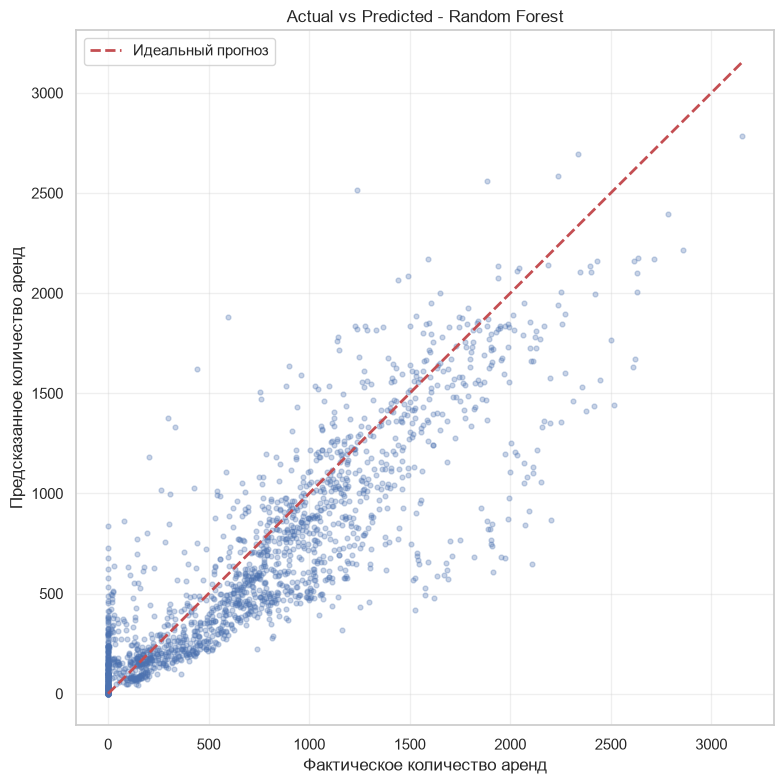

In [36]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.3, s=12)

# Определяем верхнюю границу осей, чтобы диагональ покрывала весь диапазон данных.
limit = max(float(y_test.max()), float(y_pred.max()))

# Красная диагональ - идеальный прогноз: predicted равен actual.
plt.plot([0, limit], [0, limit], "r--", linewidth=2, label="Идеальный прогноз")
plt.xlabel("Фактическое количество аренд")
plt.ylabel("Предсказанное количество аренд")
plt.title("Actual vs Predicted - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


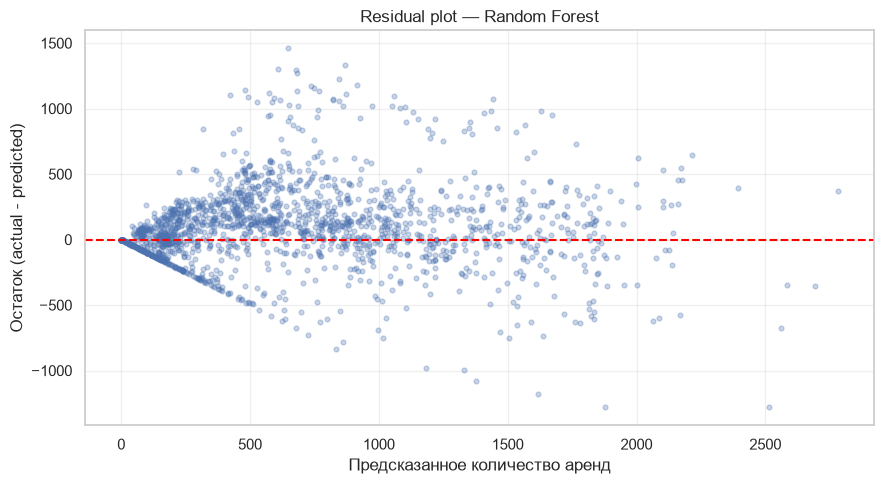

In [37]:
# Остаток считаем как actual - predicted.
# Положительный остаток означает, что модель недооценила спрос;
# отрицательный - что модель переоценила спрос.
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(9, 5))
plt.scatter(y_pred, residuals, alpha=0.3, s=12)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Предсказанное количество аренд")
plt.ylabel("Остаток (actual - predicted)")
plt.title("Residual plot — Random Forest")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Важность признаков


,feature,importance
0,num__Temperature(°C),0.384101
1,num__Hour,0.284842
2,num__Solar Radiation (MJ/m2),0.086221
3,num__Humidity(%),0.070054
4,num__Rainfall(mm),0.043575
5,num__day_of_week,0.035385
6,num__Dew point temperature(°C),0.026263
7,cat__Functioning Day_No,0.013528
8,num__month,0.013462
9,cat__Functioning Day_Yes,0.012967


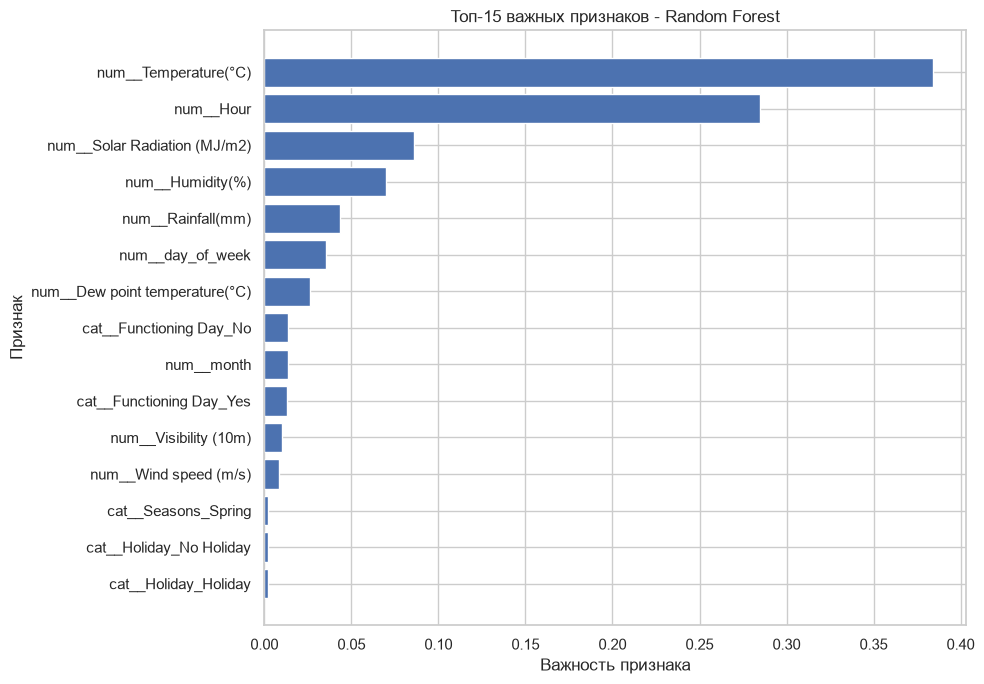

In [38]:
# Достаём уже обученные этапы pipeline: preprocessing и Random Forest.
fitted_preprocessor = rf_pipeline.named_steps["preprocessing"]
fitted_rf = rf_pipeline.named_steps["model"]

# Получаем названия признаков после преобразований.
feature_names = fitted_preprocessor.get_feature_names_out()

# Random Forest рассчитывает важность каждого преобразованного признака.
importances = fitted_rf.feature_importances_

# Объединяем названия и значения важности, сортируем по убыванию.
feature_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importances,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.head(20))

# Для графика берём 15 лидирующих признаков и сортируем их.
plt.figure(figsize=(10, 7))
top_features = feature_importance.head(15).sort_values("importance")
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Топ-15 важных признаков - Random Forest")
plt.tight_layout()
plt.show()


## 10. Итоговые выводы

1. **Температура:** среднее количество аренд растёт от отрицательных температур к диапазону 25-30 °C, где достигает примерно 1 224 аренд в час. При температуре выше 30 °C среднее значение снижается.
2. **Влажность:** наибольшее среднее количество аренд наблюдается при влажности 40-60% - около 842. При влажности 80-100% показатель снижается примерно до 346.
3. **Дождь и снег:** В дождливые часы среднее количество аренд составляет около 163, тогда как в часы без дождя около 739. В часы со снегом среднее значение составляет около 185, а без снега около 732.
4. **Ветер:** максимум среднего спроса наблюдается при 2-3 м/с - около 859. Для сильного ветра наблюдений мало.
5. **Солнечная радиация:** средний спрос возрастает примерно с 532 при низкой радиации до 974 при 2.0-3.5 MJ/m².
6. **Корреляции:** самая сильная положительная корреляция среди рассмотренных погодных факторов - у температуры (0.539), затем у солнечной радиации (0.262).
7. **Random Forest:** MAE = 219.699, RMSE = 316.196, R² = 0.734.
8. **Важность признаков для предсказаний данной модели:** Лидируют температура (0.384), час (0.285), солнечная радиация (0.086), влажность (0.070) и дождь (0.044).

